# Extracción y simulación del subgrafo Giant Fiber System (GFS) expandido

Fase **Data Understanding** (CRISP-DM). Este notebook extrae el subgrafo del circuito de escape de *Drosophila melanogaster* desde **MaleCNS v1.0** (`male-cns:v1.0`) en neuPrint, lo dibuja por capas y simula un estímulo looming. No hay modelado con el dataset de moda.

Tres capas:

- Entrada visual: `LC4` (velocidad angular) y `LPLC2` (tamaño angular).
- Decisión: `DNp01` (Giant Fiber) y `PSI`.
- Salida: `TTMn` (rama rápida) y `DLMn` (rama gradual, vía PSI).

Fuera de alcance: modelado de outfits, morfología 3D (`navis`) y la extensión `AN08B098`.

Los `bodyId` se resuelven por `type`. El token se lee del secreto de Colab `NEUPRINT_TOKEN` y no se escribe en el notebook.


## Token de neuPrint

Lee el secreto de Colab `NEUPRINT_TOKEN` y lo deja en el entorno de la sesión. El token no se escribe en ninguna celda.


In [ ]:
from google.colab import userdata
import os

# Obtener y asignar a una variable de entorno
neuprint_token = userdata.get('NEUPRINT_TOKEN')
os.environ['NEUPRINT_TOKEN'] = neuprint_token


## Instalación

Instala `neuprint-python` para consultar el conectoma. `navis` queda instalado pero no se usa: esta fase no incluye morfología 3D. `networkx`, `pandas`, `matplotlib` y `numpy` ya vienen en Colab.


In [ ]:
!pip install neuprint-python
!pip install navis

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.4/56.4 kB 3.4 MB/s eta 0:00:00
  Created wheel for asciitree: filename=asciitree-0.3.3-py3-none-any.whl size=5098 sha256=cb7608533429f78e87fb36ab83c4f0860f353fb19eb237a799104497cb0e29d4
  Stored in directory: /root/.cache/pip/wheels/0e/70/f0/bff6301cfa0d49afa79c020bc98c114a9b9c6b3048e62e3200
Successfully built asciitree
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 65.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.1/316.1 kB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 326.5/326.5 kB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 287.7/287.7 kB 24.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## Conexión

Abre el cliente de neuPrint contra el servidor público y el dataset `male-cns:v1.0`. El nombre del dataset va explícito para no consultar hemibrain ni MANC por accidente.


In [ ]:
from neuprint import Client
import os

SERVER = "https://neuprint.janelia.org"
DATASET = "male-cns:v1.0"

client = Client(SERVER, dataset=DATASET, token=os.environ["NEUPRINT_TOKEN"])
print(f"Conectado a {SERVER} dataset={DATASET}")


Conectado a https://neuprint.janelia.org dataset=male-cns:v1.0


## Verificación de nombres de tipo

Antes de fijar la lista, busca por coincidencia parcial cómo aparecen en `male-cns:v1.0` los tipos `DNp01`, `Giant Fiber`, `PSI`, `TTMn`, `DLMn`, `LC4` y `LPLC2`. Los nombres que no aparezcan se documentan como hallazgo; no se omiten en silencio.


In [ ]:
import pandas as pd

LITERATURE_NAMES = ["DNp01", "Giant Fiber", "PSI", "TTMn", "DLMn", "LC4", "LPLC2"]

PATTERNS = {
    "DNp01": r"(?i).*DNp01.*",
    "Giant Fiber": r"(?i).*[Gg]iant[ _-]?[Ff]iber.*",
    "PSI": r"(?i).*PSI.*",
    "TTMn": r"(?i).*TTMn.*",
    "DLMn": r"(?i).*DLMn.*",
    "LC4": r"(?i).*LC4.*",
    "LPLC2": r"(?i).*LPLC2.*",
}

frames = []
for label, pattern in PATTERNS.items():
    cypher = f"""
    MATCH (n:Neuron)
    WHERE n.type =~ '{pattern}'
    RETURN '{label}' AS query, n.type AS type, count(n) AS n_neurons
    ORDER BY type
    """
    hit = client.fetch_custom(cypher)
    if hit.empty:
        frames.append(pd.DataFrame({"query": [label], "type": [pd.NA], "n_neurons": [0]}))
    else:
        frames.append(hit)

type_hits = pd.concat(frames, ignore_index=True)
print("Coincidencias por nombre de la literatura:")
display(type_hits)

found = set(type_hits.loc[type_hits["n_neurons"] > 0, "type"].dropna())
missing = []
for name in PATTERNS:
    subset = type_hits.loc[type_hits["query"] == name, "type"].dropna()
    if subset.empty:
        missing.append(name)
        print(f"HALLAZGO: '{name}' no aparece como type en male-cns:v1.0")
    else:
        counts = type_hits.loc[type_hits["query"] == name, ["type", "n_neurons"]]
        print(f"{name} ->")
        print(counts.to_string(index=False))

print("Tipos distintos encontrados:", sorted(found))
print("Nombres de la literatura sin coincidencia:", missing)


Coincidencias por nombre de la literatura:


,query,type,n_neurons
0,DNp01,DNp01,2
1,Giant Fiber,<NA>,0
2,PSI,PSI,2
3,TTMn,TTMn,2
4,DLMn,"DLMn a, b",2
5,DLMn,DLMn c-f,8
6,LC4,LC4,126
7,LC4,LC40,34
8,LC4,LC41,13
9,LC4,LC43,14


DNp01 ->
 type  n_neurons
DNp01          2
HALLAZGO: 'Giant Fiber' no aparece como type en male-cns:v1.0
PSI ->
type  n_neurons
 PSI          2
TTMn ->
type  n_neurons
TTMn          2
DLMn ->
     type  n_neurons
DLMn a, b          2
 DLMn c-f          8
LC4 ->
 type  n_neurons
  LC4        126
 LC40         34
 LC41         13
 LC43         14
 LC44          5
LC46b         10
LPLC4         97
LPLC2 ->
 type  n_neurons
LPLC2        185
Tipos distintos encontrados: ['DLMn a, b', 'DLMn c-f', 'DNp01', 'LC4', 'LC40', 'LC41', 'LC43', 'LC44', 'LC46b', 'LPLC2', 'LPLC4', 'PSI', 'TTMn']
Nombres de la literatura sin coincidencia: ['Giant Fiber']


## Nombres de tipo confirmados en `male-cns:v1.0`

Búsqueda por coincidencia parcial sobre `Neuron.type`:

- `DNp01` → **`DNp01`** (2 neuronas, bilateral).
- `PSI` → **`PSI`** (2).
- `TTMn` → **`TTMn`** (2).
- `DLMn` → **`DLMn a, b`** (2) y **`DLMn c-f`** (8).
- `LC4` → **`LC4`** (126). La regex también golpeó tipos distintos que no son el detector de looming: `LC40` (34), `LC41` (13), `LC43` (14), `LC44` (5), `LC46b` (10) y `LPLC4` (97). Esos no entran en el subgrafo.
- `LPLC2` → **`LPLC2`** (185).
- `Giant Fiber` → **no aparece** como `type`. En MaleCNS el tipo es `DNp01`; `hemibrainType` de esas dos neuronas es `Giant Fiber`.

`LC4` y `LPLC2` son poblaciones, no una célula por lado. Conteos usados: 126 y 185.

Tipos del subgrafo (igualdad exacta, no por `bodyId`): `DNp01`, `PSI`, `TTMn`, `DLMn a, b`, `DLMn c-f`, `LC4`, `LPLC2`.


## Nodos

Descarga las neuronas de los tipos confirmados, de ambos lados. Conserva `bodyId`, `type`, `predictedNt` y las correspondencias `hemibrainType`, `flywireType` y `mancType` cuando existen. `side` no viene como campo en MaleCNS: se deriva del sufijo `_L`/`_R` de `instance`.


In [ ]:
from neuprint import NeuronCriteria, fetch_neurons

CONFIRMED_TYPES = [
    "DNp01",
    "PSI",
    "TTMn",
    "DLMn a, b",
    "DLMn c-f",
    "LC4",
    "LPLC2",
]
MISSING_LITERATURE_NAMES = ["Giant Fiber"]

neuron_df, _roi_counts = fetch_neurons(NeuronCriteria(type=CONFIRMED_TYPES, regex=False))

PREFERRED = [
    "bodyId",
    "type",
    "instance",
    "side",
    "predictedNt",
    "hemibrainType",
    "flywireType",
    "mancType",
]
present = [col for col in PREFERRED if col in neuron_df.columns]
missing_cols = [col for col in PREFERRED if col not in neuron_df.columns]
print("Columnas del dataset ausentes en la ontología:", missing_cols)

nodes = neuron_df[present].copy()
if "side" not in nodes.columns and "instance" in nodes.columns:
    nodes["side"] = nodes["instance"].astype(str).str.extract(r"_(L|R)$", expand=False)
    print("side no viene como campo; se derivó del sufijo _L/_R de instance.")
elif "side" in nodes.columns:
    print("side viene como campo del dataset.")

nodes = nodes.sort_values(
    [col for col in ("type", "side", "bodyId") if col in nodes.columns]
).reset_index(drop=True)
print("Conteo por tipo:")
display(nodes.groupby("type").size().rename("n").reset_index())
display(nodes.head(20))
print(f"Nodos: {len(nodes)}")


Columnas del dataset ausentes en la ontología: ['side']
side no viene como campo; se derivó del sufijo _L/_R de instance.
Conteo por tipo:


,type,n
0,"DLMn a, b",2
1,DLMn c-f,8
2,DNp01,2
3,LC4,126
4,LPLC2,185
5,PSI,2
6,TTMn,2


,bodyId,type,instance,predictedNt,hemibrainType,flywireType,mancType,side
0,801970,"DLMn a, b","DLMn a, b_L",unclear,None,None,"DLMn a, b",L
1,801295,"DLMn a, b","DLMn a, b_R",acetylcholine,None,None,"DLMn a, b",R
2,800718,DLMn c-f,DLMn c-f_L,unclear,None,None,DLMn c-f,L
3,800890,DLMn c-f,DLMn c-f_L,unclear,None,None,DLMn c-f,L
4,801895,DLMn c-f,DLMn c-f_L,unclear,None,None,DLMn c-f,L
5,803013,DLMn c-f,DLMn c-f_L,unclear,None,None,DLMn c-f,L
6,801998,DLMn c-f,DLMn c-f_R,unclear,None,None,DLMn c-f,R
7,802544,DLMn c-f,DLMn c-f_R,acetylcholine,None,None,DLMn c-f,R
8,803048,DLMn c-f,DLMn c-f_R,unclear,None,None,DLMn c-f,R
9,1050014552,DLMn c-f,DLMn c-f_R,unclear,None,None,DLMn c-f,R


Nodos: 327


## Aristas internas

Trae solo las sinapsis entre las neuronas de este subgrafo. neuPrint entrega el `weight` por ROI; se suma por par pre/post para obtener el conteo de sinapsis. Si el dataset no distingue sinapsis eléctrica y química, se deja constancia en lugar de inventar el tipo.


In [ ]:
from neuprint import fetch_adjacencies

body_ids = nodes["bodyId"].astype(int).tolist()
_adj_neurons, adj_conn = fetch_adjacencies(body_ids, body_ids)
print("Columnas de fetch_adjacencies:", list(adj_conn.columns))

conn_type_cols = [
    col
    for col in adj_conn.columns
    if col not in ("bodyId_pre", "bodyId_post", "roi", "weight")
    and any(token in col.lower() for token in ("elect", "chem", "synap", "conn"))
]
if conn_type_cols:
    print("El dataset distingue tipo de conexión:", conn_type_cols)
    edges = (
        adj_conn.groupby(["bodyId_pre", "bodyId_post", *conn_type_cols], as_index=False)["weight"]
        .sum()
    )
else:
    print(
        "HALLAZGO: las adyacencias de male-cns:v1.0 no distinguen sinapsis eléctrica y química; "
        "solo hay weight por ROI. Se suma el weight entre cada par pre/post."
    )
    edges = adj_conn.groupby(["bodyId_pre", "bodyId_post"], as_index=False)["weight"].sum()

type_lookup = nodes.set_index("bodyId")["type"]
side_lookup = nodes.set_index("bodyId")["side"]
edges["type_pre"] = edges["bodyId_pre"].map(type_lookup)
edges["type_post"] = edges["bodyId_post"].map(type_lookup)
edges["side_pre"] = edges["bodyId_pre"].map(side_lookup)
edges["side_post"] = edges["bodyId_post"].map(side_lookup)
edges = edges.sort_values("weight", ascending=False).reset_index(drop=True)
display(edges)
print(f"Aristas internas: {len(edges)}")


  0%|          | 0/2 [00:00<?, ?it/s]

0it [00:00, ?it/s]

Columnas de fetch_adjacencies: ['bodyId_pre', 'bodyId_post', 'roi', 'weight']
HALLAZGO: las adyacencias de male-cns:v1.0 no distinguen sinapsis eléctrica y química; solo hay weight por ROI. Se suma el weight entre cada par pre/post.


,bodyId_pre,bodyId_post,weight,type_pre,type_post,side_pre,side_post
0,17478,10010,86,LC4,DNp01,L,L
1,17653,10010,83,LC4,DNp01,L,L
2,518439,10010,82,LC4,DNp01,L,L
3,20859,10010,81,LC4,DNp01,L,L
4,29469,10010,73,LC4,DNp01,L,L
...,...,...,...,...,...,...,...
20679,10001,30480,1,DNp01,LC4,R,R
20680,10001,23590,1,DNp01,LPLC2,R,R
20681,10001,22328,1,DNp01,LC4,R,R
20682,10001,21804,1,DNp01,LC4,R,R


Aristas internas: 20684


## Grafo y métricas

Construye un `DiGraph` con los pesos sinápticos reales, calcula el grado de cada nodo y el camino más corto de cada `DNp01` a cada `DLMn`, y dibuja un layout exploratorio. La figura por capas (entrada, decisión, salida) va en una celda posterior.


Grafo: 327 nodos, 20684 aristas
Grado medio por tipo:


,type,in_degree,out_degree
0,"DLMn a, b",6.0,6.0
1,DLMn c-f,5.2,5.1
2,DNp01,159.5,24.0
3,LC4,52.0,45.8
4,LPLC2,74.3,80.0
5,PSI,7.5,8.0
6,TTMn,1.0,1.0


Peso total por par de tipos (las aristas individuales están en `edges`):


,type_pre,type_post,weight
16,LPLC2,LPLC2,46178
12,LC4,LC4,18392
11,LC4,DNp01,6362
14,LPLC2,DNp01,4862
15,LPLC2,LC4,2902
18,PSI,DLMn c-f,406
13,LC4,LPLC2,361
19,PSI,DNp01,95
10,DNp01,TTMn,90
4,DLMn c-f,DLMn c-f,90


Camino más corto DNp01 (GF) -> DLMn:
  DNp01:L -> DLMn a, b:L: longitud 2 | DNp01:L -> PSI:L -> DLMn a, b:L
  DNp01:L -> DLMn a, b:R: longitud 2 | DNp01:L -> PSI:R -> DLMn a, b:R
  DNp01:L -> DLMn c-f:L: longitud 2 | DNp01:L -> PSI:R -> DLMn c-f:L
  DNp01:L -> DLMn c-f:L: longitud 2 | DNp01:L -> PSI:R -> DLMn c-f:L
  DNp01:L -> DLMn c-f:L: longitud 2 | DNp01:L -> PSI:R -> DLMn c-f:L
  DNp01:L -> DLMn c-f:L: longitud 2 | DNp01:L -> PSI:R -> DLMn c-f:L
  DNp01:L -> DLMn c-f:R: longitud 2 | DNp01:L -> PSI:L -> DLMn c-f:R
  DNp01:L -> DLMn c-f:R: longitud 2 | DNp01:L -> PSI:L -> DLMn c-f:R
  DNp01:L -> DLMn c-f:R: longitud 2 | DNp01:L -> PSI:L -> DLMn c-f:R
  DNp01:L -> DLMn c-f:R: longitud 2 | DNp01:L -> PSI:L -> DLMn c-f:R
  DNp01:R -> DLMn a, b:L: longitud 2 | DNp01:R -> PSI:L -> DLMn a, b:L
  DNp01:R -> DLMn a, b:R: longitud 2 | DNp01:R -> PSI:R -> DLMn a, b:R
  DNp01:R -> DLMn c-f:L: longitud 2 | DNp01:R -> PSI:R -> DLMn c-f:L
  DNp01:R -> DLMn c-f:L: longitud 2 | DNp01:R -> PSI:R -> 

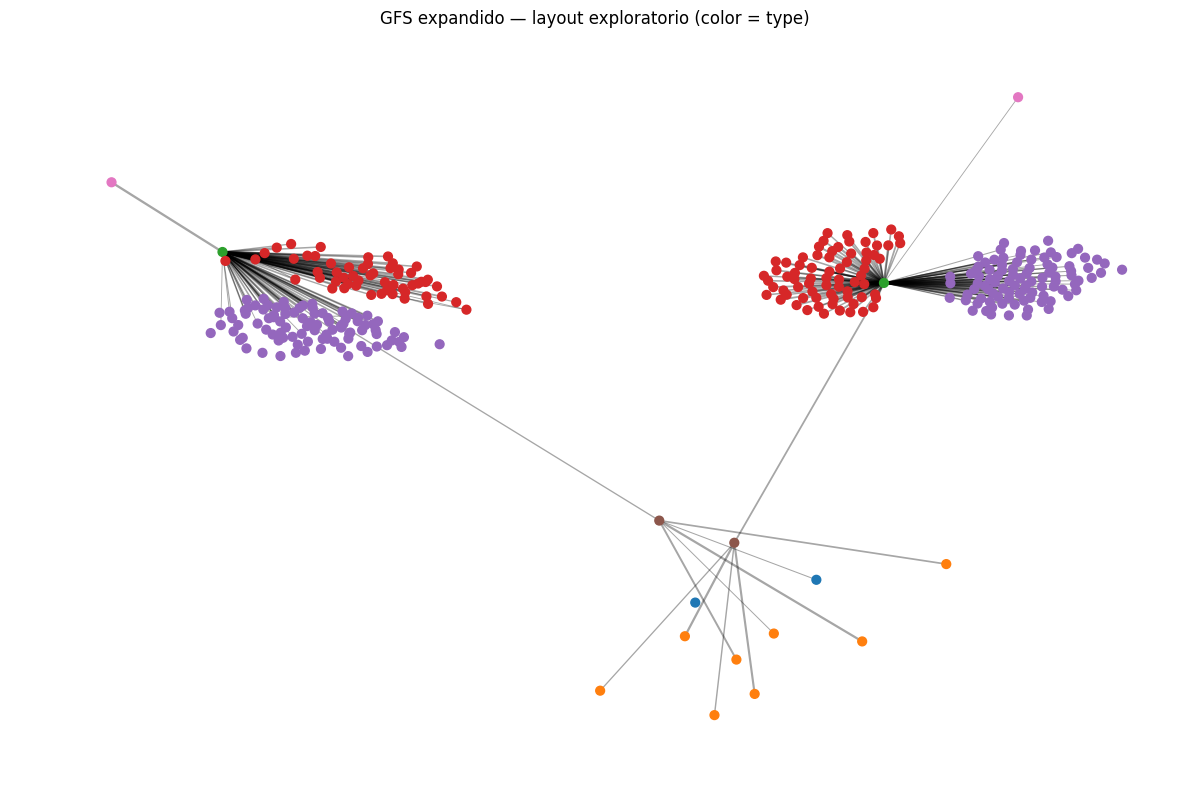

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()
attr_cols = [col for col in nodes.columns if col != "bodyId"]
for _, row in nodes.iterrows():
    attrs = {}
    for col in attr_cols:
        val = row[col]
        if pd.isna(val):
            continue
        attrs[col] = val.item() if hasattr(val, "item") and not isinstance(val, str) else val
    G.add_node(int(row["bodyId"]), **attrs)

for _, row in edges.iterrows():
    G.add_edge(int(row["bodyId_pre"]), int(row["bodyId_post"]), weight=int(row["weight"]))

print(f"Grafo: {G.number_of_nodes()} nodos, {G.number_of_edges()} aristas")

degree_table = pd.DataFrame(
    {
        "bodyId": list(G.nodes),
        "type": [G.nodes[n].get("type") for n in G.nodes],
        "side": [G.nodes[n].get("side") for n in G.nodes],
        "in_degree": [G.in_degree(n) for n in G.nodes],
        "out_degree": [G.out_degree(n) for n in G.nodes],
    }
)
print("Grado medio por tipo:")
display(
    degree_table.groupby("type")[["in_degree", "out_degree"]]
    .mean()
    .round(1)
    .reset_index()
)

print("Peso total por par de tipos (las aristas individuales están en `edges`):")
pair_weight = (
    edges.groupby(["type_pre", "type_post"], as_index=False)["weight"]
    .sum()
    .sort_values("weight", ascending=False)
)
display(pair_weight)

gf_nodes = [n for n, data in G.nodes(data=True) if data.get("type") == "DNp01"]
dlmn_nodes = [n for n, data in G.nodes(data=True) if str(data.get("type", "")).startswith("DLMn")]
print("Camino más corto DNp01 (GF) -> DLMn:")
for src in gf_nodes:
    for dst in dlmn_nodes:
        src_label = f"{G.nodes[src].get('type')}:{G.nodes[src].get('side')}"
        dst_label = f"{G.nodes[dst].get('type')}:{G.nodes[dst].get('side')}"
        try:
            path = nx.shortest_path(G, src, dst)
            labels = [f"{G.nodes[p].get('type')}:{G.nodes[p].get('side')}" for p in path]
            print(f"  {src_label} -> {dst_label}: longitud {len(path) - 1} | {' -> '.join(labels)}")
        except nx.NetworkXNoPath:
            print(f"  {src_label} -> {dst_label}: sin camino")

print("Aristas esperadas por la literatura (suma de weight por par de tipos):")
expected = [
    ("LC4", "DNp01"),
    ("LPLC2", "DNp01"),
    ("DNp01", "TTMn"),
    ("DNp01", "PSI"),
    ("PSI", "DLMn a, b"),
    ("PSI", "DLMn c-f"),
]
for pre, post in expected:
    hit = pair_weight[(pair_weight["type_pre"] == pre) & (pair_weight["type_post"] == post)]
    if hit.empty:
        print(f"  AUSENTE: {pre} -> {post}")
    else:
        print(f"  PRESENTE: {pre} -> {post}  weight={int(hit['weight'].sum())}")

PLOT_MIN_WEIGHT = 20
H = nx.DiGraph((u, v, d) for u, v, d in G.edges(data=True) if d["weight"] >= PLOT_MIN_WEIGHT)
H.add_nodes_from(G.nodes(data=True))
types = sorted({data.get("type") for _, data in G.nodes(data=True)})
cmap = plt.cm.tab10
color_of = {neuron_type: cmap(i % 10) for i, neuron_type in enumerate(types)}
pos = nx.spring_layout(G, seed=7, k=0.35)
print(f"Layout exploratorio: solo aristas con weight >= {PLOT_MIN_WEIGHT} ({H.number_of_edges()} de {G.number_of_edges()}).")
max_weight = max(data["weight"] for _, _, data in H.edges(data=True))
widths = [0.2 + 1.8 * (data["weight"] / max_weight) for _, _, data in H.edges(data=True)]
plt.figure(figsize=(12, 8))
nx.draw_networkx_nodes(
    G,
    pos,
    node_color=[color_of[G.nodes[n].get("type")] for n in G.nodes],
    node_size=40,
)
nx.draw_networkx_edges(H, pos, width=widths, alpha=0.35, arrows=False)
plt.axis("off")
plt.title("GFS expandido — layout exploratorio (color = type)")
plt.tight_layout()
plt.show()


## Visualización por capas

Dibuja el mismo grafo en tres columnas: entrada (`LC4`, `LPLC2`), decisión (`DNp01`, `PSI`) y salida (`TTMn`, `DLMn`). Las poblaciones de entrada van como puntos pequeños; decisión y salida llevan etiqueta. El grosor de la arista sigue el `weight`. Se omiten las sinapsis dentro de la capa de entrada para que se vea el camino hacia la decisión y la salida.


Aristas dibujadas (fuera de la capa de entrada): 430 de 20684


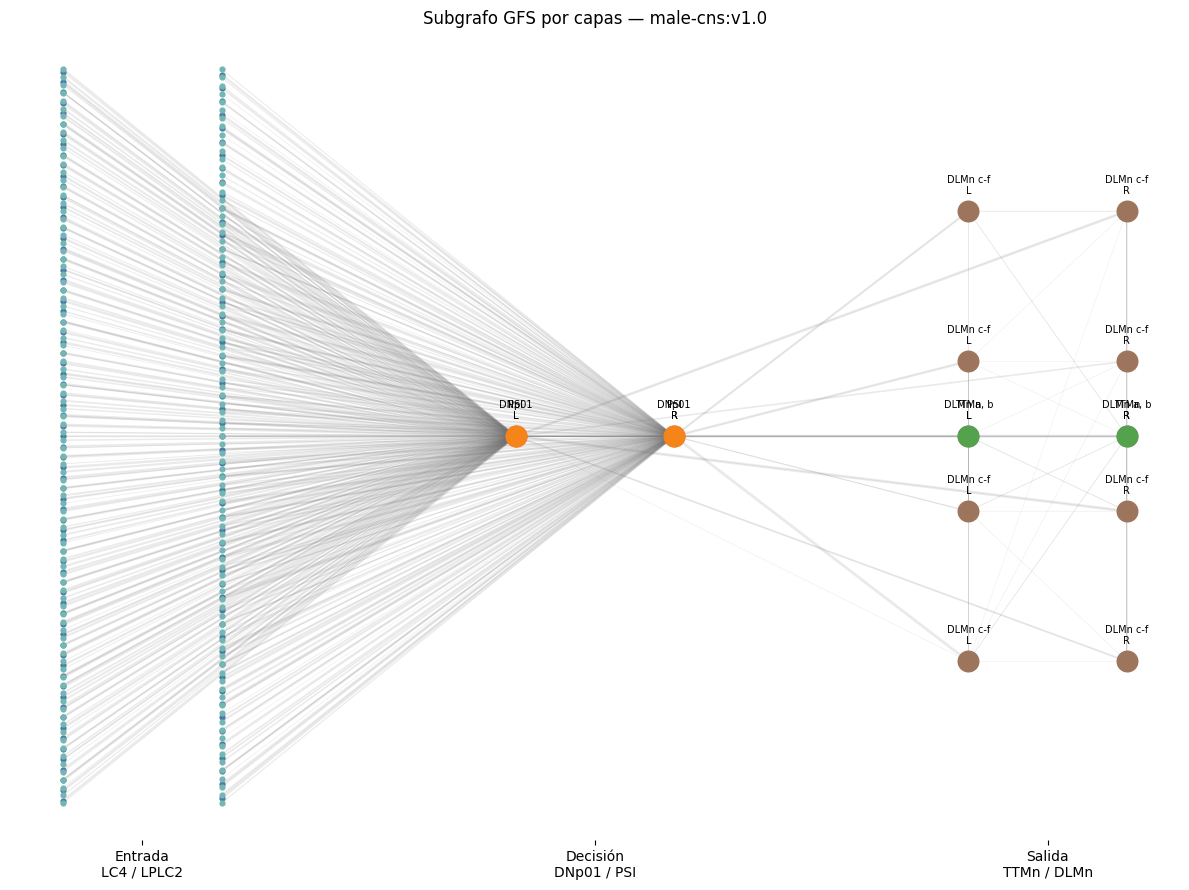

/content/gfs/gfs_layers.png


In [ ]:
from pathlib import Path

LAYER_OF = {
    "LC4": 0,
    "LPLC2": 0,
    "DNp01": 1,
    "PSI": 1,
    "TTMn": 2,
    "DLMn a, b": 2,
    "DLMn c-f": 2,
}
LAYER_X = {0: 0.0, 1: 1.6, 2: 3.2}
COLOR_OF = {
    "LC4": "#4C78A8",
    "LPLC2": "#72B7B2",
    "DNp01": "#E45756",
    "PSI": "#F58518",
    "TTMn": "#54A24B",
    "DLMn a, b": "#B279A2",
    "DLMn c-f": "#9D755D",
}

groups = {}
for node, data in G.nodes(data=True):
    groups.setdefault((LAYER_OF[data["type"]], data["type"], data.get("side")), []).append(node)

pos = {}
for (layer, _ntype, side), members in groups.items():
    members = sorted(members)
    side_shift = -0.28 if side == "L" else 0.28
    for i, node in enumerate(members):
        y = (i + 1) / (len(members) + 1)
        pos[node] = (LAYER_X[layer] + side_shift, y)

input_nodes = [n for n, data in G.nodes(data=True) if LAYER_OF[data["type"]] == 0]
labeled_nodes = [n for n in G.nodes if n not in input_nodes]
pathway = [
    (u, v, data)
    for u, v, data in G.edges(data=True)
    if not (LAYER_OF[G.nodes[u]["type"]] == 0 and LAYER_OF[G.nodes[v]["type"]] == 0)
]
max_weight = max(data["weight"] for _, _, data in pathway)
print(f"Aristas dibujadas (fuera de la capa de entrada): {len(pathway)} de {G.number_of_edges()}")

fig, ax = plt.subplots(figsize=(12, 9))
for u, v, data in pathway:
    x1, y1 = pos[u]
    x2, y2 = pos[v]
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="-",
            color="0.45",
            alpha=0.15,
            lw=0.3 + 2.2 * (data["weight"] / max_weight),
        ),
    )

for node in input_nodes:
    ax.scatter(*pos[node], s=12, c=COLOR_OF[G.nodes[node]["type"]], zorder=3)
for node in labeled_nodes:
    ax.scatter(*pos[node], s=220, c=COLOR_OF[G.nodes[node]["type"]], zorder=4)
    ax.text(
        pos[node][0],
        pos[node][1] + 0.02,
        f"{G.nodes[node]['type']}\n{G.nodes[node].get('side')}",
        ha="center",
        va="bottom",
        fontsize=7,
        zorder=5,
    )

ax.set_xticks([0, 1.6, 3.2])
ax.set_xticklabels(["Entrada\nLC4 / LPLC2", "Decisión\nDNp01 / PSI", "Salida\nTTMn / DLMn"])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("Subgrafo GFS por capas — male-cns:v1.0")
fig.tight_layout()

layers_path = Path("/content/gfs")
layers_path.mkdir(parents=True, exist_ok=True)
fig.savefig(layers_path / "gfs_layers.png", dpi=150)
plt.show()
print(layers_path / "gfs_layers.png")


## Cobertura de flyvis

`flyvis` (Lappalainen et al. 2024) es un modelo del sistema visual, no del Giant Fiber. No se instala el paquete: exige Python `<3.13` y este runtime es 3.13. Se lee la lista de nodos publicada en `fib25-fib19_v2.2.json` y se comprueba si incluye `LC4`, `LPLC2`, `DNp01` o `Giant Fiber`. Si no están, la simulación con los pesos de MaleCNS es obligatoria.


In [ ]:
import json
import urllib.request

FLYVIS_URL = (
    "https://raw.githubusercontent.com/TuragaLab/flyvis/main/"
    "flyvis/connectome/fib25-fib19_v2.2.json"
)
with urllib.request.urlopen(FLYVIS_URL, timeout=60) as response:
    flyvis_payload = json.load(response)

flyvis_types = sorted({node["name"] for node in flyvis_payload["nodes"]})
TARGETS = ["LC4", "LPLC2", "DNp01", "Giant Fiber"]
flyvis_coverage = {name: name in flyvis_types for name in TARGETS}
print(f"flyvis modela {len(flyvis_types)} tipos de lóbulo óptico.")
print("Últimos tipos de la lista:", flyvis_types[-8:])
for name, present in flyvis_coverage.items():
    print(f"  {name}: {'SÍ' if present else 'NO'}")

FLYVIS_COVERS_GFS = any(flyvis_coverage.values())
if FLYVIS_COVERS_GFS:
    print("Decisión: flyvis cubre al menos un tipo del circuito. La simulación queda como contraste, no como sustituto.")
else:
    print(
        "Decisión: flyvis NO cubre LC4, LPLC2 ni GF/DNp01. "
        "La simulación con los pesos de male-cns:v1.0 es necesaria."
    )


flyvis modela 65 tipos de lóbulo óptico.
Últimos tipos de la lista: ['TmY13', 'TmY14', 'TmY15', 'TmY18', 'TmY3', 'TmY4', 'TmY5a', 'TmY9']
  LC4: NO
  LPLC2: NO
  DNp01: NO
  Giant Fiber: NO
Decisión: flyvis NO cubre LC4, LPLC2 ni GF/DNp01. La simulación con los pesos de male-cns:v1.0 es necesaria.


## Decisión

`flyvis` modela 65 tipos del lóbulo óptico. La lista termina en tipos `TmY*` y **no incluye** `LC4`, `LPLC2`, `DNp01` ni `Giant Fiber`. Cobertura: **no**. Por eso la celda siguiente simula el looming con los pesos sinápticos reales de MaleCNS, en lugar de reutilizar ese modelo.


## Simulación de un looming

Integrador con fuga sobre el grafo real. El tamaño angular `theta(t)` crece hacia una colisión: `LPLC2` recibe el tamaño y `LC4` recibe su derivada positiva (velocidad). Cada fila de pesos se normaliza. El estado nuevo es una mezcla: se conserva una parte del estado anterior y el resto es la entrada ponderada de las otras neuronas, más el estímulo. Sin ese factor sobre el término recurrente la actividad se amplifica en cada paso y la curva se dispara. Se marca el primer cruce de un umbral fijo en la media de `TTMn` y el pico de la media de `DLMn`.


TTMn cruza 0.05 en t=7 (máximo 11.197)
Pico de DLMn medio en t=79 (valor 4.518)
Actividad máxima de cualquier tipo: 20.836


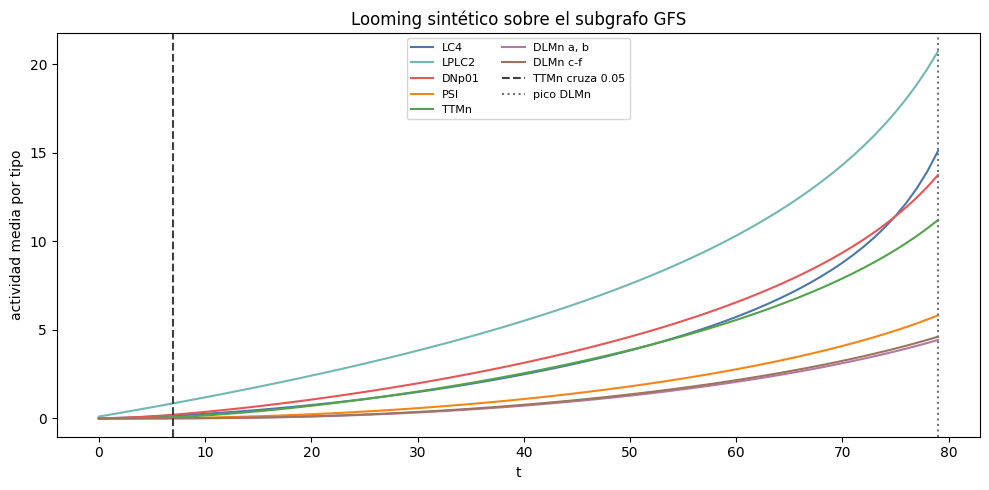

/content/gfs/simulation.png
/content/gfs/simulation_activity.csv


In [12]:
import numpy as np
from pathlib import Path

DECAY = 0.2
N_STEPS = 80
TTMN_THRESHOLD = 0.05

body_ids = [int(body_id) for body_id in nodes["bodyId"]]
index_of = {body_id: i for i, body_id in enumerate(body_ids)}
n_neurons = len(body_ids)

weights = np.zeros((n_neurons, n_neurons))
for _, row in edges.iterrows():
    post = index_of[int(row["bodyId_post"])]
    pre = index_of[int(row["bodyId_pre"])]
    weights[post, pre] += float(row["weight"])
row_sum = weights.sum(axis=1, keepdims=True)
row_sum[row_sum == 0] = 1.0
weights = weights / row_sum

def indices_for(neuron_type):
    return [index_of[int(body_id)] for body_id in nodes.loc[nodes["type"] == neuron_type, "bodyId"]]

lc4_idx = indices_for("LC4")
lplc2_idx = indices_for("LPLC2")

t = np.arange(N_STEPS)
t_hit = N_STEPS + 8
theta = 1.0 / (t_hit - t)
theta = theta / theta.max()
velocity = np.diff(theta, prepend=theta[0])
velocity = np.clip(velocity, 0, None)
velocity = velocity / velocity.max()

state = np.zeros(n_neurons)
traces = []
for step in range(N_STEPS):
    drive = np.zeros(n_neurons)
    drive[lc4_idx] = velocity[step]
    drive[lplc2_idx] = theta[step]
    state = (1 - DECAY) * state + DECAY * (weights @ state) + drive
    traces.append(state.copy())
activity = np.vstack(traces)

sim = pd.DataFrame({"t": t, "theta": theta, "velocity": velocity})
for neuron_type in CONFIRMED_TYPES:
    sim[neuron_type] = activity[:, indices_for(neuron_type)].mean(axis=1)

ttmn = sim["TTMn"].to_numpy()
dlmn_mean = sim[["DLMn a, b", "DLMn c-f"]].mean(axis=1).to_numpy()
crossings = np.flatnonzero(ttmn >= TTMN_THRESHOLD)
t_ttmn = int(crossings[0]) if len(crossings) else None
t_dlmn = int(dlmn_mean.argmax())
print(f"TTMn cruza {TTMN_THRESHOLD} en t={t_ttmn} (máximo {ttmn.max():.3f})")
print(f"Pico de DLMn medio en t={t_dlmn} (valor {dlmn_mean[t_dlmn]:.3f})")
print(f"Actividad máxima de cualquier tipo: {activity.max():.3f}")

fig, ax = plt.subplots(figsize=(10, 5))
for neuron_type, color in COLOR_OF.items():
    ax.plot(t, sim[neuron_type], label=neuron_type, color=color)
if t_ttmn is not None:
    ax.axvline(t_ttmn, color="0.25", ls="--", label=f"TTMn cruza {TTMN_THRESHOLD}")
ax.axvline(t_dlmn, color="0.45", ls=":", label="pico DLMn")
ax.set_xlabel("t")
ax.set_ylabel("actividad media por tipo")
ax.set_title("Looming sintético sobre el subgrafo GFS")
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()

out = Path("/content/gfs")
out.mkdir(parents=True, exist_ok=True)
sim_fig = out / "simulation.png"
sim_csv = out / "simulation_activity.csv"
fig.savefig(sim_fig, dpi=150)
sim.to_csv(sim_csv, index=False)
plt.show()
print(sim_fig)
print(sim_csv)


## Exportación

Guarda nodos, aristas, la resolución de tipos, las figuras y la serie de la simulación en `/content/gfs`, y dispara la descarga en el navegador. Estos archivos son la entrada de las fases siguientes.


In [ ]:
import json
from pathlib import Path
from google.colab import files

out = Path("/content/gfs")
out.mkdir(parents=True, exist_ok=True)

nodes_path = out / "nodes.csv"
edges_path = out / "edges.csv"
meta_path = out / "type_resolution.json"

nodes.to_csv(nodes_path, index=False)
edges.to_csv(edges_path, index=False)

resolution = {
    "dataset": DATASET,
    "server": SERVER,
    "confirmed_types": CONFIRMED_TYPES,
    "missing_literature_names": MISSING_LITERATURE_NAMES,
    "note": (
        "Giant Fiber no es un type en male-cns:v1.0. "
        "El tipo correspondiente es DNp01; hemibrainType de esas neuronas es 'Giant Fiber'. "
        "side no existe como campo y se derivó del sufijo _L/_R de instance. "
        "Las adyacencias no distinguen sinapsis eléctrica y química."
    ),
    "adjacency_distinguishes_electrical_vs_chemical": False,
    "side_source": "derived_from_instance_suffix",
    "n_nodes": int(len(nodes)),
    "n_edges": int(len(edges)),
}
meta_path.write_text(json.dumps(resolution, indent=2, ensure_ascii=False), encoding="utf-8")

for path in (nodes_path, edges_path, meta_path):
    print(f"{path} ({path.stat().st_size} bytes)")

for path in (nodes_path, edges_path, meta_path):
    files.download(str(path))


/content/gfs/nodes.csv (855 bytes)
/content/gfs/edges.csv (2973 bytes)
/content/gfs/type_resolution.json (640 bytes)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>